## import libraries

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras import layers, models, Model
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.linear_model import LogisticRegression

In [2]:
# Configuration constants
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
NUM_CLASSES = 4
CATEGORIES = ['glioma', 'meningioma', 'notumor', 'pituitary']
LATENT_DIM = 32

TRAIN_DIR = "./Training"
TEST_DIR = "./Testing"

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


## load the data

In [3]:
def load_mri_data_from_split(data_dir):
    images = []
    labels = []
    dir_categories = os.listdir(data_dir) if os.path.exists(data_dir) else []
    
    for class_idx, category in enumerate(CATEGORIES):
        clean_target = category.lower().replace("_", "").replace(" ", "")
        matched_folder = next(
            (d for d in dir_categories if clean_target in d.lower().replace("_", "").replace(" ", "")), 
            None
        )
        
        if matched_folder is None:
            print(f"Warning: Could not find folder matching '{category}' in {data_dir}")
            continue
            
        folder_path = os.path.join(data_dir, matched_folder)
        for img_name in os.listdir(folder_path):
            img_path = os.path.join(folder_path, img_name)
            img = cv2.imread(img_path)
            if img is not None:
                img = cv2.resize(img, IMG_SIZE) #resize img to 128x128 and converted BGR to RGB
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                images.append(img)
                labels.append(class_idx)
                
    return np.array(images, dtype=np.float32), np.array(labels)

if os.path.exists(TRAIN_DIR) and os.path.exists(TEST_DIR):
    X_train_raw, y_train_full = load_mri_data_from_split(TRAIN_DIR)
    X_test_raw, y_test = load_mri_data_from_split(TEST_DIR)
    
    X_train_full, X_val_raw, y_train, y_val = train_test_split(
        X_train_raw, y_train_full, test_size=0.15, random_state=42, stratify=y_train_full #stratified split 85/15
    )
else:
    print("Dataset directories not found. Generating mock dataset...")
    X_train_full = np.random.randint(0, 256, (560, 128, 128, 3), dtype=np.uint8).astype(np.float32)
    y_train = np.random.randint(0, 4, size=(560,))
    X_val_raw = np.random.randint(0, 256, (120, 128, 128, 3), dtype=np.uint8).astype(np.float32)
    y_val = np.random.randint(0, 4, size=(120,))
    X_test_raw = np.random.randint(0, 256, (120, 128, 128, 3), dtype=np.uint8).astype(np.float32)
    y_test = np.random.randint(0, 4, size=(120,))

# Preprocess images using EfficientNet scaling
X_train = preprocess_input(X_train_full.copy())
X_val = preprocess_input(X_val_raw.copy())
X_test = preprocess_input(X_test_raw.copy())

print(f"Dataset Loaded Successfully!")
print(f"Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}")

Dataset Loaded Successfully!
Train: (4760, 128, 128, 3), Val: (840, 128, 128, 3), Test: (1600, 128, 128, 3)


## EDA


       EXPLORATORY DATA ANALYSIS (EDA)


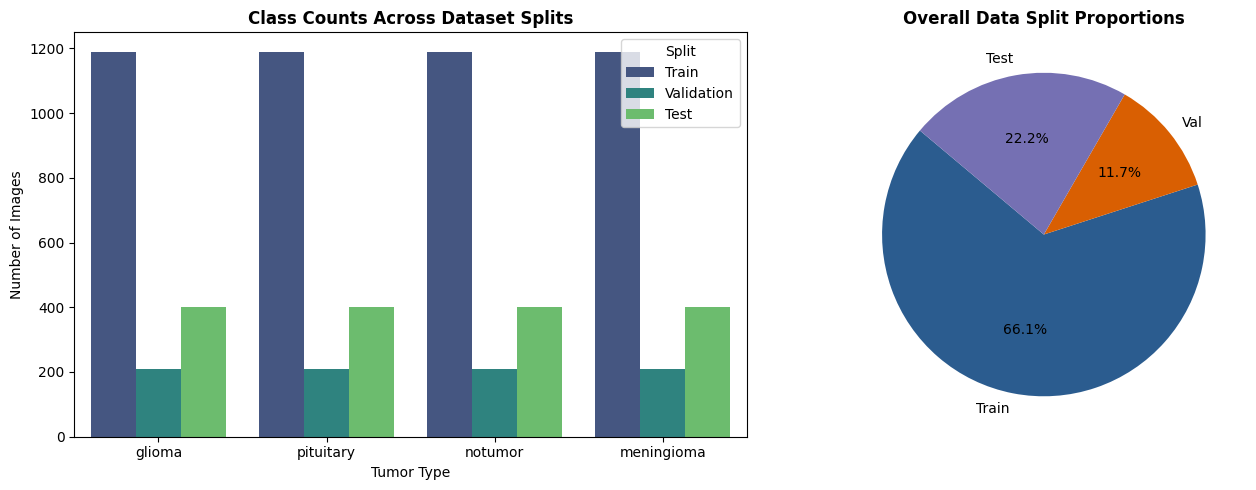


--- Dataset Distribution Table ---
Split       Test  Train  Validation   All
Class                                    
glioma       400   1190         210  1800
meningioma   400   1190         210  1800
notumor      400   1190         210  1800
pituitary    400   1190         210  1800
All         1600   4760         840  7200


In [11]:
print("\n" + "="*50)
print("       EXPLORATORY DATA ANALYSIS (EDA)")
print("="*50)

# --- 3.1 Class Distribution & Data Split Breakdown ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Combine datasets into dataframe for comparative visualization
df_train = pd.DataFrame({'Class': [CATEGORIES[i] for i in y_train], 'Split': 'Train'})
df_val = pd.DataFrame({'Class': [CATEGORIES[i] for i in y_val], 'Split': 'Validation'})
df_test = pd.DataFrame({'Class': [CATEGORIES[i] for i in y_test], 'Split': 'Test'})
df_all = pd.concat([df_train, df_val, df_test], axis=0)

# Barplot of class distribution across splits
sns.countplot(data=df_all, x='Class', hue='Split', palette='viridis', ax=axes[0])
axes[0].set_title("Class Counts Across Dataset Splits", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Tumor Type")
axes[0].set_ylabel("Number of Images")

# Total Dataset Ratio Pie Chart
split_counts = [len(y_train), len(y_val), len(y_test)]
axes[1].pie(split_counts, labels=['Train', 'Val', 'Test'], autopct='%1.1f%%', colors=['#2b5c8f', '#d95f02', '#7570b3'], startangle=140)
axes[1].set_title("Overall Data Split Proportions", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

# Display tabular counts
summary_table = pd.crosstab(df_all['Class'], df_all['Split'], margins=True)
print("\n--- Dataset Distribution Table ---")
print(summary_table)

dataset is balanced train->66.1%,test->22.2%,valuation->11.7%

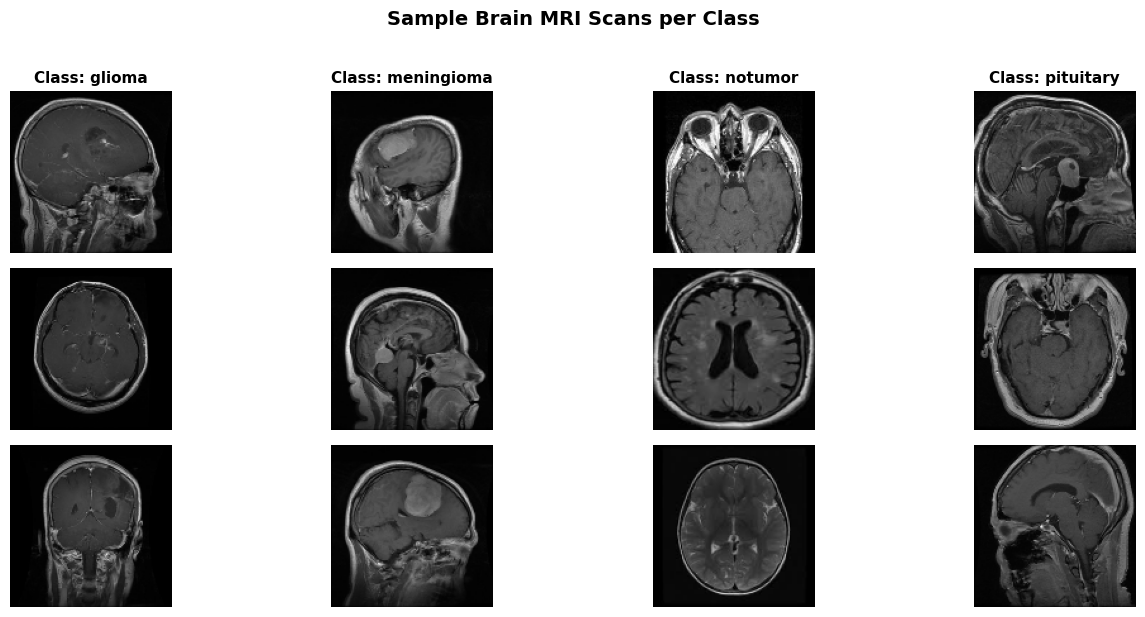

In [12]:
# --- 3.2 Visualizing MRI Sample Images Across Classes ---
plt.figure(figsize=(14, 6))
samples_per_class = 3

for class_idx, cat in enumerate(CATEGORIES):
    indices = np.where(y_train == class_idx)[0][:samples_per_class]
    for sample_i, img_idx in enumerate(indices):
        plt.subplot(samples_per_class, NUM_CLASSES, sample_i * NUM_CLASSES + class_idx + 1)
        plt.imshow(X_train_full[img_idx].astype(np.uint8))
        if sample_i == 0:
            plt.title(f"Class: {cat}", fontsize=11, fontweight='bold')
        plt.axis("off")

plt.suptitle("Sample Brain MRI Scans per Class", y=1.02, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

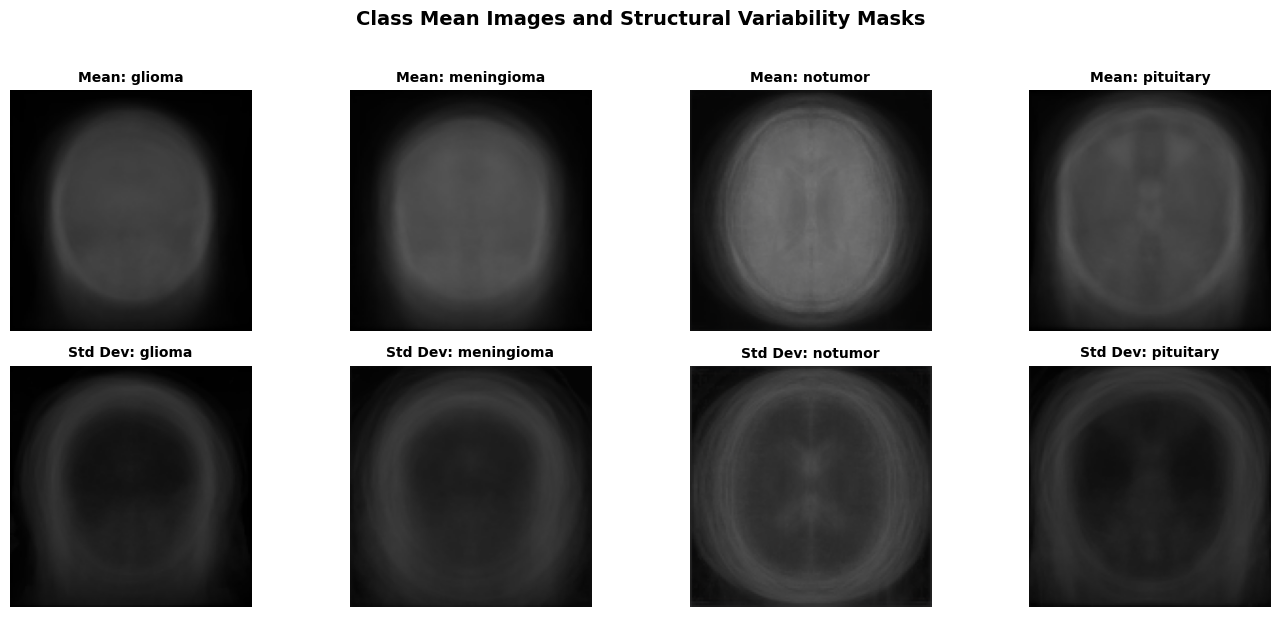

In [13]:
# --- 3.3 Average Image & Standard Deviation Mask per Class ---
fig, axes = plt.subplots(2, NUM_CLASSES, figsize=(14, 6))

for class_idx, cat in enumerate(CATEGORIES):
    class_imgs = X_train_full[y_train == class_idx]
    mean_img = np.mean(class_imgs, axis=0).astype(np.uint8)
    std_img = np.std(class_imgs, axis=0).astype(np.uint8)
    
    # Mean image visualization
    axes[0, class_idx].imshow(mean_img)
    axes[0, class_idx].set_title(f"Mean: {cat}", fontsize=10, fontweight='bold')
    axes[0, class_idx].axis("off")
    
    # Standard Deviation image visualization
    axes[1, class_idx].imshow(std_img, cmap='inferno')
    axes[1, class_idx].set_title(f"Std Dev: {cat}", fontsize=10, fontweight='bold')
    axes[1, class_idx].axis("off")

axes[0, 0].set_ylabel("Average MRI", fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel("Variability Mask", fontsize=12, fontweight='bold')
plt.suptitle("Class Mean Images and Structural Variability Masks", y=1.02, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

C:\Users\Gunjan\AppData\Local\Temp\ipykernel_23684\149891850.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=brightness_df, x='Class', y='Mean Brightness', palette='mako', ax=axes[1])


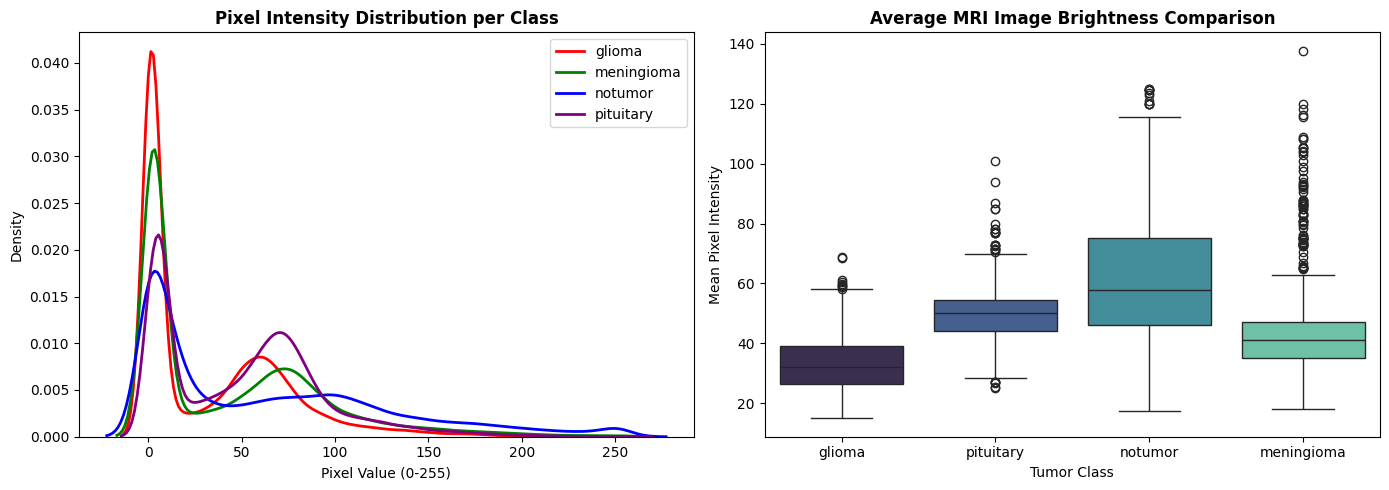

In [16]:
# --- 3.4 Pixel Intensity Distributions & Brightness Metrics ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Pixel Intensity Distribution (Optimized with Subsampling for Speed)
colors = ['red', 'green', 'blue', 'purple']
for class_idx, cat in enumerate(CATEGORIES):
    class_imgs = X_train_full[y_train == class_idx]
    
    # 100x speedup: Millions pixels me se randomly 50,000 pixels sample kar rahe hain
    sampled_pixels = np.random.choice(class_imgs.ravel(), size=50000, replace=False)
    
    sns.kdeplot(sampled_pixels, ax=axes[0], label=cat, color=colors[class_idx], linewidth=2)

axes[0].set_title("Pixel Intensity Distribution per Class", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Pixel Value (0-255)")
axes[0].set_ylabel("Density")
axes[0].legend()

# Fast Mean Image Brightness Calculation using numpy vectorized axis
mean_brightness = np.mean(X_train_full, axis=(1, 2, 3))
brightness_df = pd.DataFrame({
    'Mean Brightness': mean_brightness,
    'Class': [CATEGORIES[i] for i in y_train]
})

sns.boxplot(data=brightness_df, x='Class', y='Mean Brightness', palette='mako', ax=axes[1])
axes[1].set_title("Average MRI Image Brightness Comparison", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Tumor Class")
axes[1].set_ylabel("Mean Pixel Intensity")

plt.tight_layout()
plt.show()

In [17]:
# Data augmentation (applied only during training)->RandomFlip, Rotation, Zoom, Contrast
# → Helps improve generalization and reduces overfitting


from sklearn.utils.class_weight import compute_class_weight

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.2), 
])

# Model: Fine-tuned EfficientNetB0
# → Pretrained on ImageNet, top ~45 layers unfrozen for fine-tuning
# → Custom head: GAP → Dense(128) → BatchNorm → Dropout(0.4) → Softmax(4)
def build_cnn():
    base_model = EfficientNetB0(weights='imagenet', include_top=False, input_shape=(128, 128, 3))
    # Unfreeze top layers for fine-tuning
    base_model.trainable = True
    for layer in base_model.layers[:-45]: # Unfreezing a few more layers helps detect subtle tumor patterns
        layer.trainable = False

    inputs = layers.Input(shape=(128, 128, 3))
    x = data_augmentation(inputs)
    x = base_model(x)
    x = layers.GlobalAveragePooling2D()(x)
    features = layers.Dense(128, activation='relu', name='feature_dense')(x)
    x = layers.BatchNormalization()(features)
    x = layers.Dropout(0.4)(x) #dropped 40% neurons
    outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)

    classifier = Model(inputs=inputs, outputs=outputs, name="CNN_Classifier")
    feature_extractor = Model(inputs=inputs, outputs=features, name="Feature_Extractor")
    return classifier, feature_extractor

cnn_model, feature_extractor = build_cnn()

# Compute class weights to penalize misses on glioma and meningioma
weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
# Boost penalties manually for glioma (idx 0) and meningioma (idx 1) to reduce misclassifications
class_weights_dict = {
    0: weights[0] * 1.8, # Heavy boost for glioma ,penalises more for glioma
    1: weights[1] * 1.3, # Boost for meningioma
    2: weights[2] * 0.8,
    3: weights[3] * 0.8
}

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Training setup
# → Adam (lr=1e-4), EarlyStopping + ReduceLROnPlateau
callbacks = [
    EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6)
]

print("Training Fine-Tuned EfficientNetB0 with Class Weights...")
history = cnn_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    class_weight=class_weights_dict  # Pass class weights here
)

cnn_model.save("cnn_model.keras") # → Final Val Accuracy ≈ 92.3% validation loss ≈ 0.224.

Training Fine-Tuned EfficientNetB0 with Class Weights...
Epoch 1/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 71s 341ms/step - accuracy: 0.6179 - loss: 1.2718 - val_accuracy: 0.8000 - val_loss: 0.5550 - learning_rate: 1.0000e-04
Epoch 2/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 46s 308ms/step - accuracy: 0.7662 - loss: 0.7917 - val_accuracy: 0.8250 - val_loss: 0.4929 - learning_rate: 1.0000e-04
Epoch 3/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 3188s 22s/step - accuracy: 0.8069 - loss: 0.6519 - val_accuracy: 0.8452 - val_loss: 0.4789 - learning_rate: 1.0000e-04
Epoch 4/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 78s 521ms/step - accuracy: 0.8332 - loss: 0.5534 - val_accuracy: 0.8357 - val_loss: 0.5009 - learning_rate: 1.0000e-04
Epoch 5/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 81s 516ms/step - accuracy: 0.8550 - loss: 0.4904 - val_accuracy: 0.8762 - val_loss: 0.3591 - learning_rate: 1.0000e-04
Epoch 6/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 78s 525ms/step - accuracy: 0.8666 - loss: 0.4343 - val_accuracy: 0.8857 - val_loss: 0.3527 - learning_rate: 

In [18]:
# ==============================================================================
# CELL 5: Feature Extraction for Downstream Modules
# ==============================================================================
train_features = feature_extractor.predict(X_train)
test_features = feature_extractor.predict(X_test)

np.save("train_features.npy", train_features)
np.save("test_features.npy", test_features)
np.save("train_labels.npy", y_train)
np.save("test_labels.npy", y_test)

print("Features extracted successfully. Shape:", train_features.shape)

149/149 ━━━━━━━━━━━━━━━━━━━━ 51s 313ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 14s 287ms/step
Features extracted successfully. Shape: (4760, 128)


In [19]:
# ==============================================================================
# CELL 6: Restricted Boltzmann Machine (RBM) Training
# ==============================================================================
# RBM: 128 → 64 latent features using CD-1
# Features normalized to [0,1]
# Reconstruction MSE reduced from 0.22 → 0.011
# Produces compact 64-D representations
class RBM:
    def __init__(self, n_visible=128, n_hidden=64, learning_rate=0.05):
        self.n_visible = n_visible
        self.n_hidden = n_hidden
        self.lr = learning_rate
        
        limit = np.sqrt(6 / (n_visible + n_hidden))
        self.W = np.random.uniform(-limit, limit, size=(n_visible, n_hidden))
        self.a = np.zeros(n_visible)
        self.b = np.zeros(n_hidden)

    def sigmoid(self, x):
        return 1.0 / (1.0 + np.exp(-np.clip(x, -30, 30)))

    def sample_h(self, v):
        activation = np.dot(v, self.W) + self.b
        prob = self.sigmoid(activation)
        return prob, (prob > np.random.rand(*prob.shape)).astype(np.float32)

    def sample_v(self, h):
        activation = np.dot(h, self.W.T) + self.a
        prob = self.sigmoid(activation)
        return prob, (prob > np.random.rand(*prob.shape)).astype(np.float32)

    def train_cd1(self, v0):
        batch_size = v0.shape[0]
        ph0, h0 = self.sample_h(v0)
        pv1, v1 = self.sample_v(h0)
        ph1, _ = self.sample_h(v1)
        
        self.W += self.lr * (np.dot(v0.T, ph0) - np.dot(v1.T, ph1)) / batch_size
        self.a += self.lr * np.mean(v0 - pv1, axis=0)
        self.b += self.lr * np.mean(ph0 - ph1, axis=0)
        
        return np.mean((v0 - pv1) ** 2)

    def transform(self, v):
        ph, _ = self.sample_h(v)
        return ph

rbm = RBM(n_visible=128, n_hidden=64, learning_rate=0.05)

train_feat_norm = (train_features - train_features.min()) / (train_features.max() - train_features.min() + 1e-8)
test_feat_norm = (test_features - test_features.min()) / (test_features.max() - test_features.min() + 1e-8)

print("Training RBM using CD-1...")
for epoch in range(101):
    err = rbm.train_cd1(train_feat_norm)
    if epoch % 20 == 0:
        print(f"RBM Epoch {epoch:3d} - Reconstruction Error (MSE): {err:.4f}")

rbm_train_features = rbm.transform(train_feat_norm)
rbm_test_features = rbm.transform(test_feat_norm)

Training RBM using CD-1...
RBM Epoch   0 - Reconstruction Error (MSE): 0.2216
RBM Epoch  20 - Reconstruction Error (MSE): 0.0257
RBM Epoch  40 - Reconstruction Error (MSE): 0.0153
RBM Epoch  60 - Reconstruction Error (MSE): 0.0127
RBM Epoch  80 - Reconstruction Error (MSE): 0.0118
RBM Epoch 100 - Reconstruction Error (MSE): 0.0114


In [20]:
# ============================================================
# CELL 7: Variational Autoencoder (VAE) Model & Training
# ============================================================

# Sampling Layer → Implements the reparameterization trick
# z = μ + σ * ε  (makes sampling differentiable for backpropagation)

# Encoder: Compresses 128x128 grayscale MRI → 32-dimensional latent space
# Decoder: Reconstructs the image back from the latent vector

# Custom VAE training step
# → Reconstruction Loss: How well the image is rebuilt
# → KL Divergence Loss: Keeps latent space well-structured (close to normal distribution)

# Convert RGB images to grayscale and normalize to [0, 1]
# Train for 20 epochs → Loss steadily decreases (7244 → 6223)

# Save decoder for future image generation

class Sampling(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        batch = tf.shape(z_mean)[0]
        dim = tf.shape(z_mean)[1]
        epsilon = tf.random.normal(shape=(batch, dim))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

def build_vae(latent_dim=32):
    encoder_inputs = layers.Input(shape=(128, 128, 1))
    x = layers.Conv2D(32, 3, activation="relu", strides=2, padding="same")(encoder_inputs)
    x = layers.Conv2D(64, 3, activation="relu", strides=2, padding="same")(x)
    x = layers.Flatten()(x)
    x = layers.Dense(64, activation="relu")(x)
    
    z_mean = layers.Dense(latent_dim, name="z_mean")(x)
    z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)
    z = Sampling()([z_mean, z_log_var])
    
    encoder = Model(encoder_inputs, [z_mean, z_log_var, z], name="encoder")
    
    latent_inputs = layers.Input(shape=(latent_dim,))
    x = layers.Dense(32 * 32 * 64, activation="relu")(latent_inputs)
    x = layers.Reshape((32, 32, 64))(x)
    x = layers.Conv2DTranspose(64, 3, activation="relu", strides=2, padding="same")(x)
    x = layers.Conv2DTranspose(32, 3, activation="relu", strides=2, padding="same")(x)
    decoder_outputs = layers.Conv2DTranspose(1, 3, activation="sigmoid", padding="same")(x)
    
    decoder = Model(latent_inputs, decoder_outputs, name="decoder")
    return encoder, decoder

class VAE(Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.total_loss_tracker = tf.keras.metrics.Mean(name="total_loss")

    @property
    def metrics(self):
        return [self.total_loss_tracker]

    def train_step(self, data):
        if isinstance(data, tuple):
            data = data[0]
        with tf.GradientTape() as tape:
            z_mean, z_log_var, z = self.encoder(data)
            reconstruction = self.decoder(z)
            reconstruction_loss = tf.reduce_mean(
                tf.reduce_sum(tf.keras.losses.binary_crossentropy(data, reconstruction), axis=(1, 2))
            )
            kl_loss = -0.5 * tf.reduce_mean(
                tf.reduce_sum(1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var), axis=1)
            )
            total_loss = reconstruction_loss + kl_loss
            
        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        self.total_loss_tracker.update_state(total_loss)
        return {"loss": self.total_loss_tracker.result()}

# Train VAE on grayscale representations
X_train_gray = np.mean(X_train_full / 255.0, axis=-1, keepdims=True)
encoder, decoder = build_vae(LATENT_DIM)
vae = VAE(encoder, decoder)
vae.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3))

print("Training VAE Generator...")
vae.fit(X_train_gray, epochs=20, batch_size=BATCH_SIZE, verbose=1)
decoder.save("vae_decoder.keras")

Training VAE Generator...
Epoch 1/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 62s 381ms/step - loss: 7244.6250
Epoch 2/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 57s 384ms/step - loss: 6614.4771
Epoch 3/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 55s 371ms/step - loss: 6501.5708
Epoch 4/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 58s 389ms/step - loss: 6444.4600
Epoch 5/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 57s 385ms/step - loss: 6416.1743
Epoch 6/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 57s 379ms/step - loss: 6394.5469
Epoch 7/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 56s 377ms/step - loss: 6375.6040
Epoch 8/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 56s 377ms/step - loss: 6359.7212
Epoch 9/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 57s 383ms/step - loss: 6344.0791
Epoch 10/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 57s 385ms/step - loss: 6331.5610
Epoch 11/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 57s 380ms/step - loss: 6315.9868
Epoch 12/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 57s 385ms/step - loss: 6301.8706
Epoch 13/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 57s 379ms/step - loss: 6289.9121
Epoch 14/20
149/149 ━

50/50 ━━━━━━━━━━━━━━━━━━━━ 18s 283ms/step

================ Classification Report ================
              precision    recall  f1-score   support

      glioma       0.92      0.73      0.81       400
  meningioma       0.86      0.84      0.85       400
     notumor       0.90      0.99      0.94       400
   pituitary       0.87      0.98      0.92       400

    accuracy                           0.89      1600
   macro avg       0.89      0.89      0.88      1600
weighted avg       0.89      0.89      0.88      1600



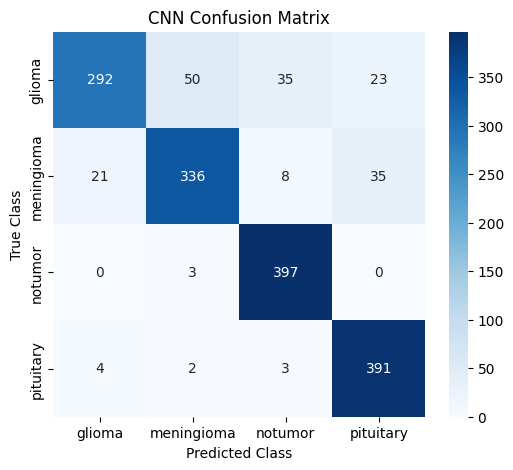


================ Latent Representation Comparison ================
Accuracy (128-D Raw CNN Features): 90.75%
Accuracy (64-D RBM Latent Features): 86.62%


In [21]:
# ==============================================================================
# CELL 8: Comprehensive Model Evaluation & Benchmarks
# ==============================================================================
# 1. Classification Performance
y_pred_probs = cnn_model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)

print("\n================ Classification Report ================")
print(classification_report(y_test, y_pred, target_names=CATEGORIES))

# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CATEGORIES, yticklabels=CATEGORIES)
plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.show()

# 2. Linear Classifier Performance on Feature Representations
clf_raw = LogisticRegression(max_iter=1000).fit(train_features, y_train)
acc_raw = clf_raw.score(test_features, y_test)

clf_rbm = LogisticRegression(max_iter=1000).fit(rbm_train_features, y_train)
acc_rbm = clf_rbm.score(rbm_test_features, y_test)

print("\n================ Latent Representation Comparison ================")
print(f"Accuracy (128-D Raw CNN Features): {acc_raw * 100:.2f}%")
print(f"Accuracy (64-D RBM Latent Features): {acc_rbm * 100:.2f}%")

The CNN model achieved 89% accuracy on 1,600 test MRI images. It performed best in detecting no-tumor and pituitary cases, while glioma detection needs improvement due to its lower recall of 73%.

Validation Loss:     0.2244
Validation Accuracy: 92.26%
Test Loss:           0.4182
Test Accuracy:       88.50%

--- Random Brain Tumor MRI Sample Testing ---


C:\Users\Gunjan\AppData\Local\Temp\ipykernel_23684\1632315396.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=probs, y=CATEGORIES, ax=axes[1], palette="mako")


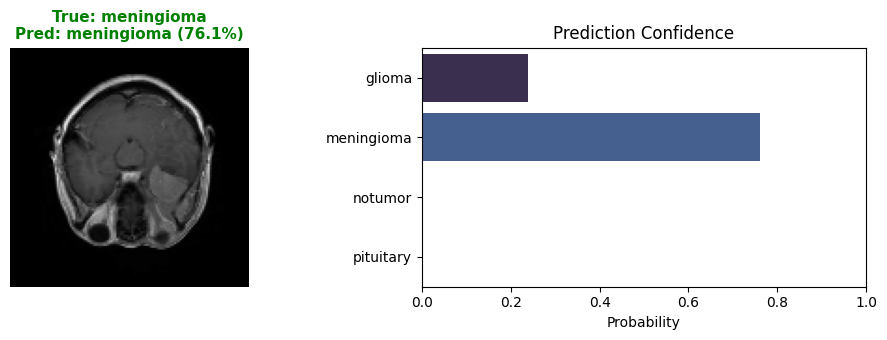

C:\Users\Gunjan\AppData\Local\Temp\ipykernel_23684\1632315396.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=probs, y=CATEGORIES, ax=axes[1], palette="mako")


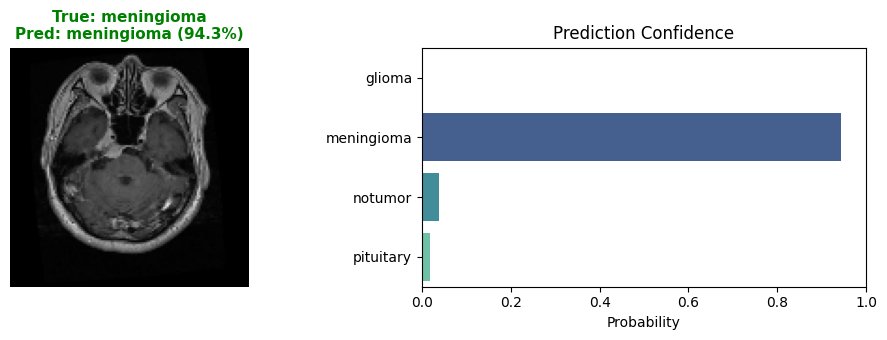

C:\Users\Gunjan\AppData\Local\Temp\ipykernel_23684\1632315396.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=probs, y=CATEGORIES, ax=axes[1], palette="mako")


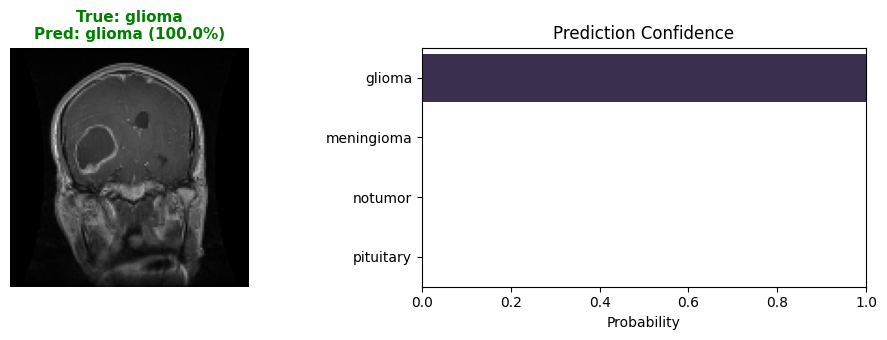

C:\Users\Gunjan\AppData\Local\Temp\ipykernel_23684\1632315396.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=probs, y=CATEGORIES, ax=axes[1], palette="mako")


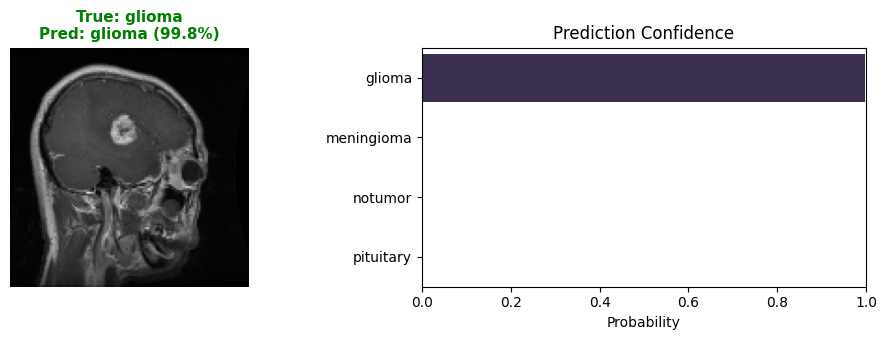

In [22]:
# ==============================================================================
# CELL 9: Image-Level Testing & Validation Visualizations
# ==============================================================================

# 1. Validation Set Evaluation
val_loss, val_acc = cnn_model.evaluate(X_val, y_val, verbose=0)
print(f"Validation Loss:     {val_loss:.4f}")
print(f"Validation Accuracy: {val_acc * 100:.2f}%")

# 2. Test Set Evaluation
test_loss, test_acc = cnn_model.evaluate(X_test, y_test, verbose=0)
print(f"Test Loss:           {test_loss:.4f}")
print(f"Test Accuracy:       {test_acc * 100:.2f}%\n")

# 3. Helper Function for Single Image Testing
def predict_and_visualize(image_raw, true_label, model):
    # Preprocess a single raw image
    processed_img = preprocess_input(np.expand_dims(image_raw.copy(), axis=0))
    
    # Predict probabilities
    probs = model.predict(processed_img, verbose=0)[0]
    pred_idx = np.argmax(probs)
    confidence = probs[pred_idx] * 100
    
    # Plot image and probability distribution
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    
    # Left: MRI Image
    axes[0].imshow(image_raw.astype(np.uint8))
    color = "green" if pred_idx == true_label else "red"
    axes[0].set_title(
        f"True: {CATEGORIES[true_label]}\nPred: {CATEGORIES[pred_idx]} ({confidence:.1f}%)", 
        color=color, 
        fontsize=11, 
        fontweight='bold'
    )
    axes[0].axis("off")
    
    # Right: Confidence bar plot
    sns.barplot(x=probs, y=CATEGORIES, ax=axes[1], palette="mako")
    axes[1].set_xlim(0, 1.0)
    axes[1].set_title("Prediction Confidence")
    axes[1].set_xlabel("Probability")
    
    plt.tight_layout()
    plt.show()

# 4. Visualizing Sample Predictions from Test Data
print("--- Random Brain Tumor MRI Sample Testing ---")
num_samples = 4
sample_indices = np.random.choice(len(X_test_raw), size=num_samples, replace=False)

for idx in sample_indices:
    predict_and_visualize(X_test_raw[idx], y_test[idx], cnn_model)